# Fig. S29: selection of pseudotime-associated genes by mutual information

Draws the four panels of this figure from the tables of an `mi/` run (`MI_RUN`) into `OUT`: the MI distributions
of human (A) and mouse (B) genes significant at FDR < 0.05 with the 90th-percentile cutoff, and the significance (C)
and fold enrichment (D) of the human-mouse overlap of top genes across percentile cutoffs. `OUT` must be a new folder
outside the repository and outside `xmens_figures`; copy the checked files into `xmens_figures` by hand.

Inputs (sha256-checked): `MI_RUN/mi_mouse.csv`, `MI_RUN/mi_human.csv` (gene, mi in nats, p, q) and
`MI_RUN/overlap/ortholog_pairs_one2one.csv` (Ensembl 116 strict one-to-one pairs). The sweep over cutoffs is recomputed
here and checked against the run's `overlap/overlap_percentile_sweep.csv` and `overlap/methods_overlap.json`, so the
figure and the Methods numbers come from the same tables.

Outputs: `S29_mi_gene_selection_<DATE>.svg` (full figure), `.png` (preview), `panels/..._{a,b,c,d}.svg`, the cutoff
sweep CSV, the caption with the numbers filled in, and a provenance JSON (inputs and outputs by sha256).

MI is estimated in nats (scikit-learn k-nearest-neighbor estimator, `mi/scripts/`) and shown in bits
(1 bit = ln 2 nats).
Drawing code as the figure of record (`tmp/2026_10_30_s29_5f_bigheat/mi_gene_selection_figS29_fibdec_latent/`).


In [1]:
# Parameters (papermill -p NAME VALUE overrides them)
OUT = "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_s29"  # new folder, outside the repository and xmens_figures
MI_RUN = "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_xmens_mi_final_ids"  # the mi/ run of record
DATE = "20261113"  # goes into the file names
FONT_FILE = "/usr/share/fonts/urw-base35/NimbusSans-Regular.otf"  # Helvetica clone; "": DejaVu Sans


In [2]:
import datetime
import hashlib
import json
import platform
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import font_manager
from scipy.stats import hypergeom

assert OUT, "set OUT, the folder for this figure"
OUT = Path(OUT).resolve()
REPOSITORY = Path.cwd().resolve().parent  # this notebook runs from figures/
assert "xmens_figures" not in OUT.parts, "write to OUT; copy the checked files into xmens_figures by hand"
assert REPOSITORY not in OUT.parents, f"OUT must be outside the repository ({REPOSITORY}), e.g. on netscratch"
assert not OUT.exists(), f"{OUT} exists; use a new folder"
PANEL_DIR = OUT / "panels"
PANEL_DIR.mkdir(parents=True)
MI_RUN = Path(MI_RUN)
STEM = f"S29_mi_gene_selection_{DATE}"

# Input file per table and its sha256 (the final mi/ run: steps 1-3 of 12 Nov 2026, steps 4-6 of 13 Nov with
# Ensembl-ID pairs).
INPUTS = {
    "mouse": (MI_RUN / "mi_mouse.csv", "f6f13684ff6571ce1e3a108ac760001a209f28bb8cf5a9fc272129d2dbf0528a"),
    "human": (MI_RUN / "mi_human.csv", "51decdd0a59c01b25e8f4157cafd01acf57d42442a0943bbe15132abfeb8a0b7"),
    "pairs": (MI_RUN / "overlap" / "ortholog_pairs_one2one.csv",
              "241da03d2847b6b99df1da2f7517035a5047e0791d54798f03189f86a126dae7"),
}

NATS_PER_BIT = np.log(2)
SIGNIFICANCE_Q = 0.05
CUTOFF_PERCENTILE = 90
PERCENTILES = range(40, 100)

BLUE, ORANGE, GREY = "#3b75af", "#ef8636", "0.55"
MM = 1 / 25.4


In [3]:
# Every user-visible string, so a relabel is a one-line change.
LABELS = {
    "title_human": "Human pseudotime-associated genes",
    "title_mouse": "Mouse pseudotime-associated genes",
    "title_significance": "Overlap significance vs. cutoff",
    "title_enrichment": "Overlap enrichment vs. cutoff",
    "mi_axis": "Mutual information (bits)",
    "genes_axis": "Genes",
    "cutoff_axis": "Percentile cutoff",
    "neglog10p_axis": r"$-\log_{10}(p)$",
    "fold_axis": "Fold enrichment (obs./exp.)",
    "below_cutoff": "below cutoff",
    "top": "top 10%",
    "percentile_line": "90th percentile",
    "null_band": "null 95%",
    "observed": "observed",
}


In [4]:
def set_up_font(font_file: str) -> str:
    """The family of a font file if given (e.g. Helvetica Neue, or its clone Nimbus Sans), else DejaVu Sans."""
    family = ["DejaVu Sans"]
    if font_file:
        font_manager.fontManager.addfont(font_file)
        family = [font_manager.FontProperties(fname=font_file).get_name(), "DejaVu Sans"]
    mpl.rcParams.update({"font.family": family})
    return font_manager.FontProperties(family=family).get_name()


# Plot settings of the figure of record (the figure-style ladder 7 / 6 / 5.5 pt).
plt.rcdefaults()
mpl.rcParams.update({
    "axes.labelsize": 7.0, "axes.linewidth": 0.6, "axes.spines.right": False, "axes.spines.top": False,
    "axes.titlelocation": "left", "axes.titlesize": 7.0, "font.size": 7.0, "legend.fontsize": 6.0,
    "legend.frameon": False, "lines.linewidth": 1.2, "patch.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.dpi": 300.0, "xtick.labelsize": 5.5, "xtick.major.size": 3.0,
    "xtick.major.width": 0.6, "ytick.labelsize": 5.5, "ytick.major.size": 3.0, "ytick.major.width": 0.6,
    "svg.fonttype": "none", "svg.hashsalt": "xmens",  # text stays editable; output is deterministic
})
FONT = set_up_font(FONT_FILE)
print(f"font: {FONT}")


font: Nimbus Sans


## Inputs

In [5]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


def input_path(key):
    """Path of an input after checking its sha256 against INPUTS."""
    path, expected = INPUTS[key]
    found = sha256(path)
    if found != expected:
        raise ValueError(f"{path}: sha256 {found}, expected {expected}")
    return path


mi = {species: pd.read_csv(input_path(species)).set_index("gene") for species in ("mouse", "human")}
for table in mi.values():
    table["mi"] = table["mi"] / NATS_PER_BIT  # nats -> bits
significant = {species: table[table.q < SIGNIFICANCE_Q] for species, table in mi.items()}

pairs = pd.read_csv(input_path("pairs"))
background = pairs[pairs.mouse.isin(significant["mouse"].index) & pairs.human.isin(significant["human"].index)].copy()
background["mi_mouse"] = significant["mouse"].mi.reindex(background.mouse).to_numpy()
background["mi_human"] = significant["human"].mi.reindex(background.human).to_numpy()

for species in ("human", "mouse"):
    print(f"{species}: {len(mi[species]):,} genes tested, {len(significant[species]):,} significant")
print(f"background: {len(background):,} one-to-one orthologs significant in both species")


human: 15,354 genes tested, 15,187 significant
mouse: 14,016 genes tested, 14,016 significant
background: 9,800 one-to-one orthologs significant in both species


## Overlap of top genes across percentile cutoffs

In [6]:
def overlap_at(percentile):
    """Top genes = MI above the percentile among each species' significant genes; overlap tested in the background."""
    mi_mouse, mi_human = significant["mouse"].mi.to_numpy(), significant["human"].mi.to_numpy()
    cutoff_mouse, cutoff_human = np.percentile(mi_mouse, percentile), np.percentile(mi_human, percentile)
    top_mouse, top_human = background.mi_mouse > cutoff_mouse, background.mi_human > cutoff_human
    n_background, n_mouse, n_human = len(background), int(top_mouse.sum()), int(top_human.sum())
    shared = int((top_mouse & top_human).sum())
    expected = n_mouse * n_human / n_background
    null_low, null_high = hypergeom.ppf([0.025, 0.975], n_background, n_mouse, n_human) / expected
    return dict(percentile=percentile, thr_mouse=cutoff_mouse, thr_human=cutoff_human,
                top_mouse_genomewide=int((mi_mouse > cutoff_mouse).sum()),
                top_human_genomewide=int((mi_human > cutoff_human).sum()),
                N=n_background, K_mouse=n_mouse, n_human=n_human, overlap=shared, expected=expected,
                fold=shared / expected,
                neglog10_p=-hypergeom.logsf(shared - 1, n_background, n_mouse, n_human) / np.log(10),
                null_fold_lo=null_low, null_fold_hi=null_high, pct_of_human_top=100 * shared / n_human)


sweep = pd.DataFrame([overlap_at(p) for p in PERCENTILES])
sweep.to_csv(OUT / f"{STEM}_cutoff_sweep.csv", index=False)
at_cutoff = sweep.set_index("percentile").loc[CUTOFF_PERCENTILE]
print(f"cutoff MI: human {at_cutoff.thr_human:.3f} bits, mouse {at_cutoff.thr_mouse:.3f} bits")
print(f"top genes: {int(at_cutoff.top_human_genomewide):,} human, {int(at_cutoff.top_mouse_genomewide):,} mouse")
print(f"shared {int(at_cutoff.overlap)} (expected {at_cutoff.expected:.1f}; {at_cutoff.fold:.2f}-fold; "
      f"-log10 p = {at_cutoff.neglog10_p:.1f})")


cutoff MI: human 0.035 bits, mouse 0.105 bits
top genes: 1,519 human, 1,402 mouse
shared 379 (expected 144.8; 2.62-fold; -log10 p = 84.3)


## Check against the run's own overlap step

The `mi/` run computes the same sweep (step 4, `overlap/overlap_percentile_sweep.csv`, thresholds in nats) and the
Methods numbers (`overlap/methods_overlap.json`). Both must agree with what this notebook draws.

In [7]:
pipeline_sweep = pd.read_csv(MI_RUN / "overlap" / "overlap_percentile_sweep.csv")
pipeline_sweep[["thr_mouse", "thr_human"]] /= NATS_PER_BIT  # nats -> bits, as drawn
columns = [c for c in sweep.columns if c in pipeline_sweep.columns]
merged = sweep.merge(pipeline_sweep, on="percentile", suffixes=("", "_pipeline"))
assert len(merged) == len(sweep), "the pipeline sweep does not cover the same percentiles"
for column in columns:
    if column == "percentile":
        continue
    assert np.allclose(merged[column], merged[f"{column}_pipeline"], rtol=1e-6, atol=1e-9), f"{column} differs"
print(f"sweep: {len(columns) - 1} columns x {len(merged)} cutoffs agree with the pipeline's step 4")

methods = json.loads((MI_RUN / "overlap" / "methods_overlap.json").read_text())
expected_numbers = {"N": methods["N"], "K_mouse": methods["K"], "n_human": methods["n"], "overlap": methods["k"],
                    "top_mouse_genomewide": methods["mouse"]["top"], "top_human_genomewide": methods["human"]["top"]}
for key, value in expected_numbers.items():
    assert int(at_cutoff[key]) == value, f"{key}: notebook {int(at_cutoff[key])}, methods_overlap.json {value}"
assert np.isclose(at_cutoff.neglog10_p, -methods["log10_p"], rtol=1e-6)
print("at the 90th percentile: N, K, n, k, top genes and log10 p agree with methods_overlap.json")


sweep: 14 columns x 60 cutoffs agree with the pipeline's step 4
at the 90th percentile: N, K, n, k, top genes and log10 p agree with methods_overlap.json


## Panels

In [8]:
def format_p(neglog10):
    exponent = int(np.floor(neglog10))
    mantissa = 10 ** (exponent - neglog10 + 1)
    return f"p = {mantissa:.1f} × 10$^{{-{exponent + 1}}}$"


def draw_mi_histogram(ax, species):
    values = significant[species].mi.to_numpy()
    cutoff = np.percentile(values, CUTOFF_PERCENTILE)
    bins = np.linspace(0, values.max() * 1.001, 101)
    ax.hist(values[values <= cutoff], bins=bins, histtype="step", color=BLUE, lw=1.1, label=LABELS["below_cutoff"])
    ax.hist(values[values > cutoff], bins=bins, histtype="step", color=ORANGE, lw=1.1, label=LABELS["top"])
    ax.axvline(cutoff, color="k", ls=(0, (4, 2)), lw=1.2, label=LABELS["percentile_line"])
    ax.set_yscale("log")
    ax.set_ylim(0.6, None)
    ax.set_xlabel(LABELS["mi_axis"])
    ax.set_ylabel(LABELS["genes_axis"])
    ax.set_title(LABELS[f"title_{species}"], loc="left")
    ax.legend(loc="upper right", frameon=False, handlelength=1.6)
    ax.margins(x=0.02)


def draw_significance(ax):
    ax.plot(sweep.percentile, sweep.neglog10_p, "-o", color=BLUE, ms=2.2, lw=1)
    ax.axvline(CUTOFF_PERCENTILE, color="k", ls=(0, (4, 2)), lw=1)
    ax.annotate(format_p(at_cutoff.neglog10_p), xy=(CUTOFF_PERCENTILE, at_cutoff.neglog10_p), xytext=(42, 45),
                textcoords="data", ha="left", va="center", fontsize=mpl.rcParams["legend.fontsize"],
                arrowprops=dict(arrowstyle="-", color="0.3", lw=0.6, shrinkA=2, shrinkB=2))
    ax.set_xlabel(LABELS["cutoff_axis"])
    ax.set_ylabel(LABELS["neglog10p_axis"])
    ax.set_ylim(0, None)
    ax.set_title(LABELS["title_significance"], loc="left")
    ax.margins(x=0.03)


def draw_enrichment(ax):
    ax.fill_between(sweep.percentile, sweep.null_fold_lo, sweep.null_fold_hi, color=GREY, alpha=0.35, lw=0,
                    label=LABELS["null_band"])
    ax.axhline(1, color=GREY, lw=0.8)
    ax.plot(sweep.percentile, sweep.fold, "-o", color=BLUE, ms=2.2, lw=1, label=LABELS["observed"])
    ax.axvline(CUTOFF_PERCENTILE, color="k", ls=(0, (4, 2)), lw=1)
    ax.annotate(f"{at_cutoff.fold:.2f}-fold", xy=(CUTOFF_PERCENTILE, at_cutoff.fold), xytext=(-8, 18),
                textcoords="offset points", ha="right", fontsize=mpl.rcParams["legend.fontsize"],
                arrowprops=dict(arrowstyle="-", color="0.3", lw=0.6))
    ax.set_xlabel(LABELS["cutoff_axis"])
    ax.set_ylabel(LABELS["fold_axis"])
    ax.set_ylim(0, None)
    ax.set_title(LABELS["title_enrichment"], loc="left")
    ax.legend(loc="upper left", frameon=False, handlelength=1.4)
    ax.margins(x=0.03)


PANELS = {"a": lambda ax: draw_mi_histogram(ax, "human"), "b": lambda ax: draw_mi_histogram(ax, "mouse"),
          "c": draw_significance, "d": draw_enrichment}


## Full figure

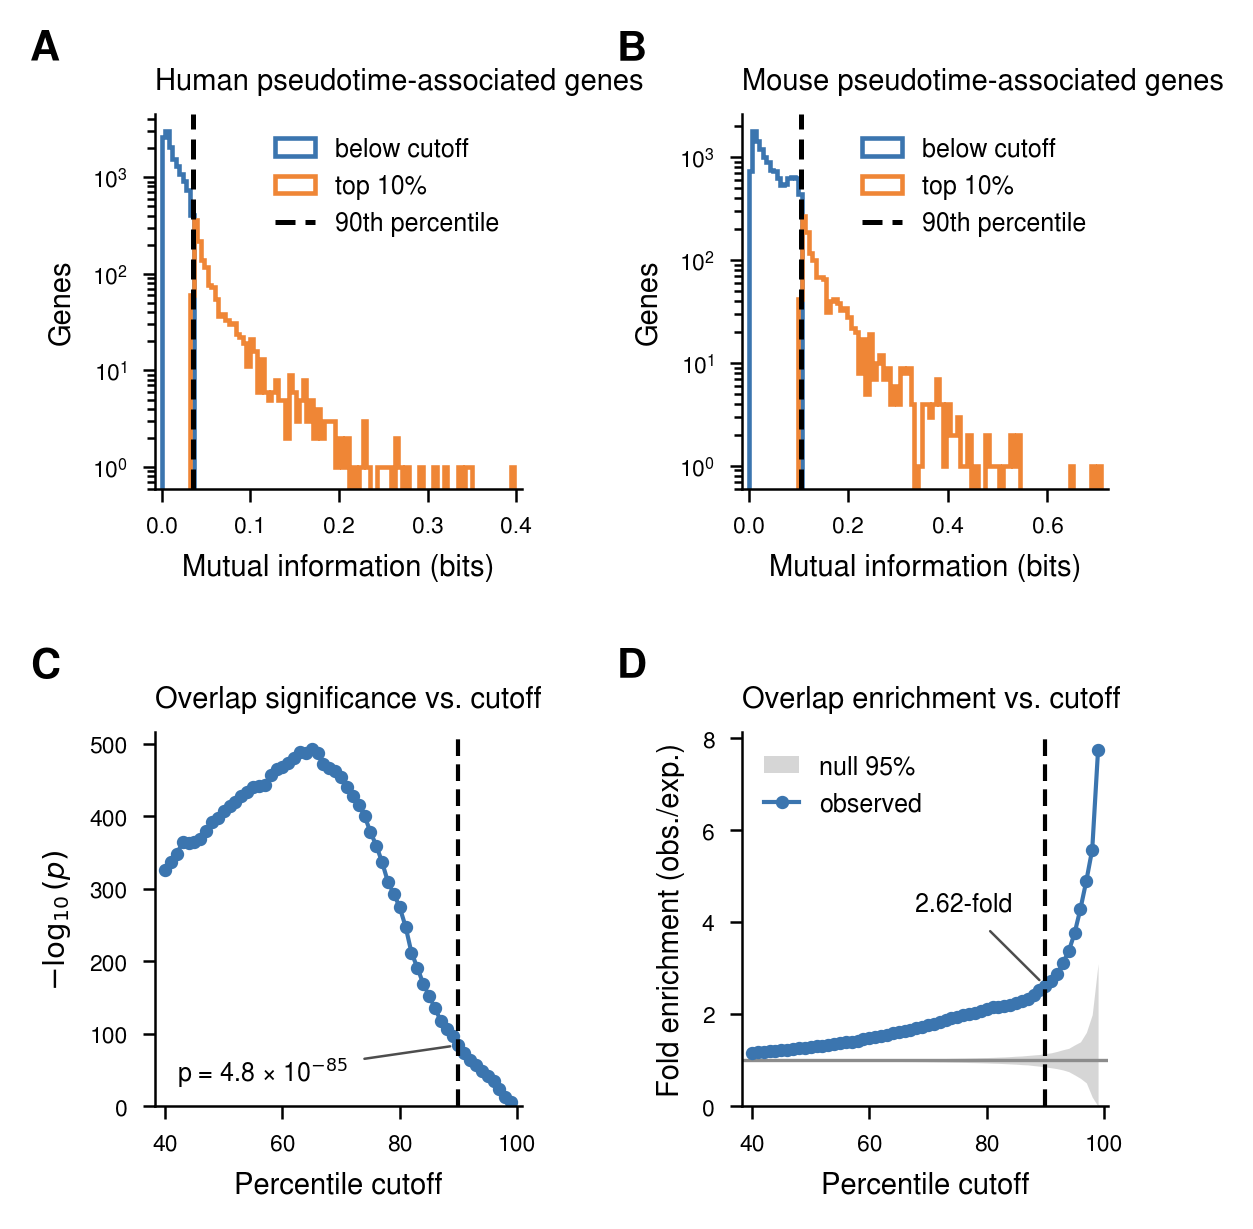

In [9]:
# 2 x 2 grid, as in the supplement: A, B (MI distributions) above C, D (overlap vs. cutoff).
WIDTH_MM, HEIGHT_MM = 95, 100
fig, axes = plt.subplots(2, 2, figsize=(WIDTH_MM * MM, HEIGHT_MM * MM),
                         gridspec_kw=dict(wspace=0.6, hspace=0.65, left=0.13, right=0.98, bottom=0.09, top=0.93))
for ax, (letter, draw) in zip(axes.flat, PANELS.items()):
    draw(ax)
    ax.text(-0.34, 1.12, letter.upper(), transform=ax.transAxes, fontweight="bold", fontsize=10, va="bottom")
fig.savefig(OUT / f"{STEM}.svg", metadata={"Date": None})
fig.savefig(OUT / f"{STEM}.png", dpi=300)
plt.close(fig)
display(Image(filename=str(OUT / f"{STEM}.png"), width=600))


## Individual panels

In [10]:
# One SVG per panel: same axes size as in the full figure, no panel letter.
axes_width = axes.flat[0].get_position().width * WIDTH_MM * MM
axes_height = axes.flat[0].get_position().height * HEIGHT_MM * MM
for letter, draw in PANELS.items():
    fig, ax = plt.subplots(figsize=(axes_width + 0.55, axes_height + 0.45))
    fig.subplots_adjust(left=0.45 / (axes_width + 0.55), right=1 - 0.1 / (axes_width + 0.55),
                        bottom=0.35 / (axes_height + 0.45), top=1 - 0.1 / (axes_height + 0.45))
    draw(ax)
    fig.savefig(PANEL_DIR / f"{STEM}_{letter}.svg", metadata={"Date": None})
    plt.close(fig)
print(sorted(p.name for p in PANEL_DIR.glob("*.svg")))


['S29_mi_gene_selection_20261113_a.svg', 'S29_mi_gene_selection_20261113_b.svg', 'S29_mi_gene_selection_20261113_c.svg', 'S29_mi_gene_selection_20261113_d.svg']


## Caption and provenance

In [ ]:
# The caption keeps the wording of the published legend; every number comes from the tables above.
SUPERSCRIPT = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")


def format_p_unicode(neglog10):
    """p as 'm.m × 10⁻ᵉ' from -log10 p, the same rounding as the panel C annotation."""
    exponent = int(np.floor(neglog10))
    mantissa = 10 ** (exponent - neglog10 + 1)
    return f"{mantissa:.1f} × 10" + f"-{exponent + 1}".translate(SUPERSCRIPT)


n_tested = {species: len(table) for species, table in mi.items()}
n_significant = {species: len(table) for species, table in significant.items()}
caption = (
    "**Fig. S29. Selection of pseudotime-associated genes based on mutual information.** Distribution of mutual "
    "information (MI) between gene expression and rank-normalized diffusion pseudotime for (**A**) human and (**B**) "
    f"mouse genes significant at FDR < 0.05 ({n_significant['human']:,} of {n_tested['human']:,} human and "
    f"{n_significant['mouse']:,} of {n_tested['mouse']:,} mouse genes detected in ≥1% of fibroblasts and decidual "
    "cells; mouse pseudotime excludes apoptotic decidual cells). Genes above the 90th percentile (dashed line; "
    f"MI = {at_cutoff.thr_human:.3f} bits in human, {at_cutoff.thr_mouse:.3f} in mouse) are designated top "
    f"pseudotime-associated genes (orange; {int(at_cutoff.top_human_genomewide):,} human, "
    f"{int(at_cutoff.top_mouse_genomewide):,} mouse). (**C**) Significance (−log₁₀ p, hypergeometric test) and "
    "(**D**) fold enrichment (observed / expected) of the overlap between the human and mouse top gene sets as a "
    f"function of the percentile cutoff, over a background of {int(at_cutoff.N):,} strict one-to-one orthologs "
    "(Ensembl 116) expressed in ≥1% of cells and significant in both species. Grey band in D, 95% interval of the "
    "overlap expected by chance (hypergeometric). At the 90th percentile (dashed line), "
    f"{int(at_cutoff.overlap)} of {int(at_cutoff.n_human):,} human and {int(at_cutoff.K_mouse):,} mouse top genes "
    f"in the background are shared ({at_cutoff.pct_of_human_top:.0f}% of the human set; {at_cutoff.expected:.1f} "
    f"expected; {at_cutoff.fold:.2f}-fold; p = {format_p_unicode(at_cutoff.neglog10_p)}).\n"
)
(OUT / f"{STEM}_caption.md").write_text(caption)

# Provenance: inputs and outputs by sha256, and the numbers quoted in the caption at full precision.
outputs = [OUT / f"{STEM}.svg", OUT / f"{STEM}.png", OUT / f"{STEM}_cutoff_sweep.csv", OUT / f"{STEM}_caption.md"]
outputs += sorted(PANEL_DIR.glob(f"{STEM}_*.svg"))
provenance = {
    "figure": "S29", "written": datetime.datetime.now().isoformat(timespec="seconds"), "host": platform.node(),
    "notebook": "figures/S29_mi_gene_selection.ipynb", "mi_run": str(MI_RUN),
    "parameters": {"OUT": str(OUT), "DATE": DATE, "FONT_FILE": FONT_FILE}, "font": FONT,
    "inputs": {key: {"path": str(path), "sha256": expected} for key, (path, expected) in INPUTS.items()},
    "checked_against": {"sweep": str(MI_RUN / "overlap" / "overlap_percentile_sweep.csv"),
                        "methods": str(MI_RUN / "overlap" / "methods_overlap.json")},
    "outputs": {str(path): sha256(path) for path in outputs},
    "at_90th_percentile": {key: (value.item() if hasattr(value, "item") else value)
                           for key, value in at_cutoff.items()},
    "n_tested": n_tested, "n_significant": n_significant,
    "software": {"python": platform.python_version(), "matplotlib": mpl.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__},
}
(OUT / f"{STEM}_provenance.json").write_text(json.dumps(provenance, indent=1))
print(caption)
print("wrote", sorted(p.name for p in OUT.iterdir()))
